# Cross-Africa Satellite Prediction: Explaining Country-Level Accuracy (NBK 4)

Thus far, we have produced two accuracy metrics per country per outcome:
- R² (absolute accuracy, often negative when predictions are biased), and
- Spearman ρ (ranking skill)

This notebook regresses each metric on observable country characteristics: urbanization, label mean and variance, number of ADM1 regions, training-set size, and geographic region. This is done to identify what structurally predicts when satellite-based prediction can be trusted. Both metrics are reported because they capture different things: R² reflects the overall calibration of the prediction, while ρ reflects whether the model correctly orders regions from worst-off to best-off (which is what matters for policy targeting).

---

### Import statements

In [23]:
import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import helpers
from sklearn.preprocessing import StandardScaler

---

### Preliminary: R² versus Spearman ρ across countries

Before running the explanatory regressions, we can see how each metric behaves across countries. R² is harsh, as a biased but correctly-ranked model shows negative R². On the other hand, Spearman ρ is magnitude-invariant and captures whether regions are ranked correctly even when absolute predictions are off. For a policy use case like targeting the worst-off regions for intervention, ranking is what matters most.

In [13]:
metrics = pd.read_csv(os.path.join(helpers.OUT, "loco_metrics.csv"))

rank_vs_abs = metrics.groupby("outcome").agg(median_r2  = ("r2", "median"),
    pct_r2_positive = ("r2", lambda s: (s > 0).mean() * 100),
    median_rho = ("spearman_rho", "median"),
    pct_rho_positive = ("spearman_rho", lambda s: (s > 0).mean() * 100),
).round(2)
rank_vs_abs

,median_r2,pct_r2_positive,median_rho,pct_rho_positive
outcome,,,,
dtp3age1,-2.31,13.04,0.15,69.57
gap_eye,-1.48,14.63,0.29,60.98
iwi,-0.41,34.88,0.49,95.35
iwipov70,-1.05,33.33,0.40,97.62
shdi,-0.94,24.53,0.45,86.79
stunting,-0.87,12.50,0.36,85.00
u5mort,-0.70,14.63,0.31,82.93


In every outcome the median R² is negative while the median Spearman ρ is positive, and typically ≥80% of countries have positive ρ. This gap matters: the model's absolute predictions are biased, but it still ranks regions correctly in most countries. The regressions below examine both metrics to understand what structural country features drive each.

---

### Building the country-level feature table

Country characteristics that could plausibly explain prediction accuracy are:
- number of ADM1 regions (does more test data stabilize accuracy?),
- mean urban share (do more urban countries predict better?),
- geographic region (does Africa split into easier/harder sub-continents?),
- label mean and variance per outcome (are extreme or heterogeneous outcomes harder?), and
- training set size

In [15]:
labels = pd.read_csv(os.path.join(helpers.PROC, "labels_augmented.csv"))
country_feats = labels.groupby("isocode3").agg(
    n_regions_total = ("gdlcode", "count"),
    urban_mean = ("urban", "mean"),
    geo_region = ("geo_region", "first"),
    country = ("country", "first"),
).reset_index()
print(f"Country feature table: {len(country_feats)} countries")
country_feats.head()

Country feature table: 54 countries


,isocode3,n_regions_total,urban_mean,geo_region,country
0,AGO,18,55.484444,Central,Angola
1,BDI,5,10.332000,East,Burundi
2,BEN,6,40.500000,West,Benin
3,BFA,13,21.936154,West,Burkina Faso
4,BWA,10,NaN,Southern,Botswana


Each country gets one row of characteristics that are constant across outcomes.

---

### Primary regression: country-level ρ on country characteristics

For each outcome, we can fit OLS regression with Spearman ρ as the dependent variable. Predictors include ADM1 count, urbanization, label mean, label variance, training-set size, and geographic region (one-hot, Central Africa as reference). The per-outcome model R² quantifies how much of the variation in country-level ranking skill is explained by these observable characteristics.

In [24]:
PREDICTORS = ["n_regions", "urban_mean", "label_mean", "label_variance", "n_train"]

def fit_explanation(target_col):
    rows = []
    for outcome in helpers.OUTCOMES:
        sub = metrics[metrics["outcome"] == outcome].copy().drop(columns=["geo_region"], errors="ignore")
        if len(sub) < 10:
            continue
        merged = sub.merge(country_feats, on="isocode3", how="left")
        merged["label_mean"]     = merged["y_true_mean"]
        merged["label_variance"] = merged["y_true_std"] ** 2
        X = merged[PREDICTORS].copy()
        X = pd.concat([X, pd.get_dummies(merged["geo_region"], prefix="geo", drop_first=True).astype(float)], axis=1)
        X = X.dropna()
        y = merged.loc[X.index, target_col]

        # Standardize numeric predictors (keep dummies as 0/1)
        numeric_cols = ["n_regions", "urban_mean", "label_mean", "label_variance", "n_train"]
        sc = StandardScaler()
        X[numeric_cols] = sc.fit_transform(X[numeric_cols])

        model = sm.OLS(y, sm.add_constant(X)).fit()
        for var, coef in model.params.items():
            rows.append({"outcome": outcome, "variable": var, "coef": coef,
                         "pvalue": model.pvalues[var], "n_countries": len(y),
                         "r2_of_model": model.rsquared, "target": target_col})
    return pd.DataFrame(rows), model

rho_df, _ = fit_explanation("spearman_rho")

rho_summary = (rho_df.groupby("outcome")[["r2_of_model", "n_countries"]].first()
               .rename(columns={"r2_of_model": "R² of ρ-explanation model"}).round(3))
rho_summary

,R² of ρ-explanation model,n_countries
outcome,,
dtp3age1,0.378,22
gap_eye,0.134,40
iwi,0.137,42
iwipov70,0.154,41
shdi,0.370,42
stunting,0.148,39
u5mort,0.155,40


Model fit is modest across outcomes (R² ≈ 0.13 – 0.38), suggesting that ranking skill variation across countries is not well-explained by the observable features used here. This could reflect genuine robustness (ρ is less sensitive to country-level heterogeneity than R²), limited statistical power at ~40 countries, or the absence of better explanatory variables (climate, governance, data-collection quality).

---

### Which characteristics significantly predict ranking skill?

A loose threshold of p < 0.1 is used because sample sizes are small (~40 countries per outcome). Given the modest model fit above, the expectation is that few predictors will reach significance.

In [25]:
print("Significant predictors (p < 0.1) of Spearman ρ by outcome:\n")
for outcome in helpers.OUTCOMES:
    sig = rho_df[(rho_df["outcome"] == outcome) & (rho_df["pvalue"] < 0.1) & (rho_df["variable"] != "const")]
    if len(sig) == 0:
        print(f"  {outcome:<10}  (no significant predictors)")
        continue
    terms = [f"{row['variable']}({row['coef']:+.3f})" for _, row in sig.iterrows()]
    print(f"  {outcome:<10}  " + ", ".join(terms))

Significant predictors (p < 0.1) of Spearman ρ by outcome:

  iwi         (no significant predictors)
  iwipov70    (no significant predictors)
  stunting    (no significant predictors)
  u5mort      (no significant predictors)
  dtp3age1    (no significant predictors)
  gap_eye     (no significant predictors)
  shdi        urban_mean(+0.145), geo_West(+0.352)


Across six of seven outcomes, no observable country characteristic significantly predicts ranking skill at p < 0.1. SHDI is the exception, where urbanization and West-Africa membership marginally predict stronger ranking performance. This null result indicates either (a) satellite ranking skill being structurally robust across country types, or (b) the regression being underpowered given the modest number of countries and the variables we measured.

---

### Explaining variation in absolute accuracy (R²)

We can now repeat the same regression using R² as the dependent variable. Although R² is harsher than ρ, penalizing both bias and poor ranking, country characteristics often predict it well because absolute accuracy is sensitive to label distribution and country-level heterogeneity. Comparing the two regressions tells us whether the same drivers matter for both metrics, or whether country features explain magnitude-level errors more than rank-level ones.

In [26]:
r2_df, _ = fit_explanation("r2")
r2_summary = (r2_df.groupby("outcome")[["r2_of_model", "n_countries"]].first()
              .rename(columns={"r2_of_model": "R² of R²-explanation model"}).round(3))
r2_summary

,R² of R²-explanation model,n_countries
outcome,,
dtp3age1,0.248,22
gap_eye,0.441,40
iwi,0.523,42
iwipov70,0.449,41
shdi,0.362,42
stunting,0.478,39
u5mort,0.315,40


Absolute accuracy is much more sensitive to country-level features: label distribution, urbanization, geographic region all plausibly shift how far predictions deviate in magnitude. Model fits are substantially higher than for ρ, meaning the same country features explain more of the variation in absolute accuracy.

---

### Visualizing coefficients across outcomes

We can plot side-by-side coefficient bars for each predictor, with Spearman-based coefficients in blue and R²-based coefficients in orange. Consistent directions across both signal robust structural effects, whereas sign flips indicate R² is capturing magnitude-bias effects that ρ is immune to.

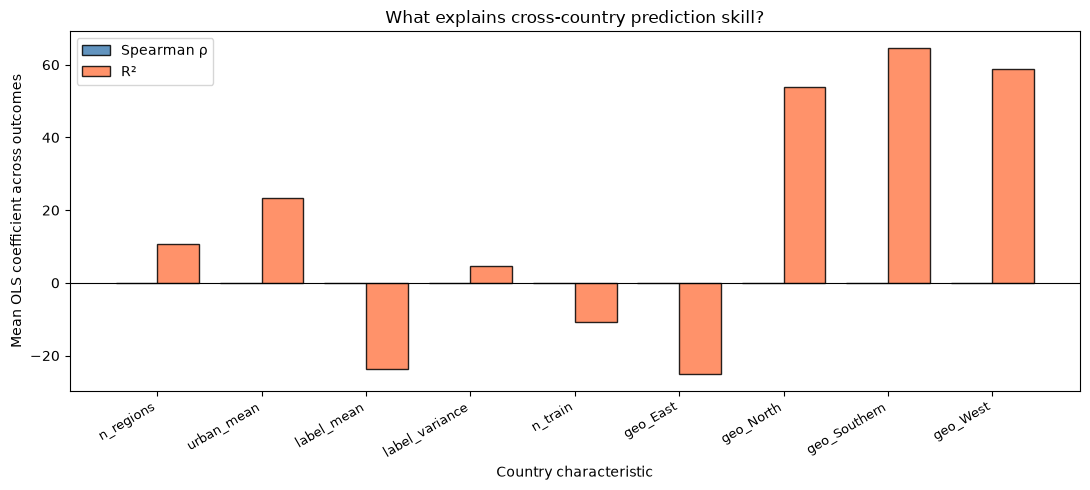

In [27]:
VARS_PLOT = ["n_regions", "urban_mean", "label_mean", "label_variance", "n_train",
             "geo_East", "geo_North", "geo_Southern", "geo_West"]

combined = (pd.concat([rho_df.assign(metric="Spearman ρ"), r2_df.assign(metric="R²")])
             .groupby(["metric", "variable"])["coef"].mean().reset_index())

fig, ax = plt.subplots(figsize=(11, 5))
width = 0.4
x = np.arange(len(VARS_PLOT))
for i, (metric, color) in enumerate([("Spearman ρ", "steelblue"), ("R²", "coral")]):
    coefs = [combined[(combined["metric"] == metric) & (combined["variable"] == v)]["coef"].values[0]
             if ((combined["metric"] == metric) & (combined["variable"] == v)).any() else 0
             for v in VARS_PLOT]
    ax.bar(x + (i - 0.5) * width, coefs, width, label=metric, color=color, alpha=0.85, edgecolor="k")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x); ax.set_xticklabels(VARS_PLOT, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Mean OLS coefficient across outcomes")
ax.set_xlabel("Country characteristic")
ax.set_title("What explains cross-country prediction skill?")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(helpers.FIG, "fig_explain_accuracy.png"), dpi=150)
plt.show()

R²-based coefficients (orange) are visibly larger in magnitude than ρ-based coefficients (blue) across all predictors, so much so that the ρ bars are nearly invisible on this shared axis. This is because country characteristics barely shift ranking skill but strongly shift absolute accuracy. Within the R² results, the signs are coherent: geographic region (North, Southern, West relative to Central), urbanization, and label mean each predict magnitude-level errors in interpretable ways. The visual contrast between the two metrics indicates that ρ is robust to country-level heterogeneity, while R² is not.

---

### Saving outputs

Coefficient tables for both targets are stacked into a single `explain_accuracy.csv` with a `target` column indicating whether each row comes from the ρ or R² regression. The combined figure is saved to `figures/fig_explain_accuracy.png`.

In [8]:
out_df = pd.concat([rho_df, r2_df], ignore_index=True)
out_df.to_csv(os.path.join(helpers.OUT, "explain_accuracy.csv"), index=False)
print(f"Saved {len(out_df)} rows to explain_accuracy.csv")

Saved 140 rows to explain_accuracy.csv


---